# 作业1 （ridge+线性回归）
0927
- 使用 Python + NumPy，不直接调用 sklearn 线性回归模型，编程实现线性回归（解析解 + 梯度下降）；
- 数据集：网上数据集或者自己构造带噪声的合成数据集。
- 训练过程：
    - 绘制损失、模型参数随迭代次数的变化曲线；调学习率观察收敛变化；
    - 可视化：训练散点 + 拟合直线或平面（单变量、2变量时）

# 数据集

In [13]:
# 加载清洗数据集
import sys, pathlib
sys.path.append( str (pathlib.Path.cwd().parent))

from my_datasets.iris_utils import load_iris_ready
x_train, x_test, y_train, y_test, scaler = load_iris_ready() # 数据集处理单独封装，达到复用目的

display(x_train)
display(y_train)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
30,-1.192531,0.035465,-1.143600,-1.222275
31,-0.454691,0.701825,-1.201142,-0.959728
80,-0.331718,-1.519376,0.122339,-0.040816
88,-0.208745,-0.186656,0.294967,0.221730
55,-0.085771,-0.630896,0.525137,0.221730
...,...,...,...,...
102,1.635854,-0.186656,1.330734,1.271916
100,0.652068,0.479705,1.388277,1.797009
44,-0.823611,1.590305,-0.970972,-0.959728
132,0.775042,-0.630896,1.158106,1.403189


30         setosa
31         setosa
80     versicolor
88     versicolor
55     versicolor
          ...    
102     virginica
100     virginica
44         setosa
132     virginica
117     virginica
Name: species, Length: 119, dtype: str

# 单变量

## 解析解法
<!-- ![image.png](./第二章%20线性模型_pages/单变量-解析解法/page_014.png) -->
<img src="../hw_01/第二章%20线性模型_pages/单变量-解析解法/page_014.png" width="50%">

重点：编程实现3.7和38公式（★Ridge 版：3.7 分母加 λ，3.8 不变）

### ★新增：Ridge（二范数正则化）版本
课件 part2 p22-23：**方差大（过拟合）时的对策之一是正则化**；p24 给出 **Ridge 损失（二范数约束）**：

<img src="./第二章%20线性模型_part2_pages/误差来源/page_024.png" width="45%">

**E(w, b) = 1/(2m)·[ Σ(f(xᵢ)−yᵢ)² + λ·w² ]**（单变量只有 w 一个惩罚对象，**偏置 b 不惩罚**）

对 w 求偏导置零可得 **解析解：公式 (3.7) 分母加 λ，公式 (3.8) 不变**（下方代码 ★ 标注部分）

### 课件只有多变量形式 → 单变量（标量）公式这样推导（★ 本节代码的来历）
<img src="./第二章%20线性模型_part2_pages/ridge回归/page_028.png" width="52%">

课件 p28 正规方程只有矩阵形式 **w̃ = (XᵀX + λ·D)⁻¹Xᵀy**（D = diag(0, 1, …, 1)，首对角元为 0 → 偏置不惩罚）。
单变量时给 X 首列补 1、参数合并为 w̃ = (b, w)ᵀ，则 **D = diag(0, 1)**，正规方程退化为 **2×2 标量方程组**：

　　m·b ＋ (Σxᵢ)·w ＝ Σyᵢ
　　(Σxᵢ)·b ＋ (Σxᵢ² ＋ λ)·w ＝ Σxᵢyᵢ

由第一式得 b = (Σyᵢ − w·Σxᵢ)/m，代入第二式消去 b 并整理，即得**标量形式解析解**：

- **w ＝ Σ yᵢ(xᵢ − x̄) ／ [ Σxᵢ² − (1/m)·(Σxᵢ)² ＋ λ ]** → 正是 **公式 (3.7) 分母加 λ**（λ=0 退回普通 (3.7)）
  对应代码：`(y * (x - x_bar)).sum() / (np.sum(x**2) - x.sum()**2 / m + lam)`
- **b ＝ (1/m)·Σ(yᵢ − w·xᵢ) ＝ ȳ − w·x̄** → **公式 (3.8) 不变**（D 首对角元 = 0，偏置不被收缩）
  对应代码：`(y - w * x).sum() / m`


In [5]:
# 单变量线性回归 —— 解析解（Ridge 二范数正则化版；课件《单变量-解析解法》p14 + part2 p24/p28）
# 损失函数: E(w,b) = 1/(2m)·[ Σ(yᵢ − w·xᵢ − b)² + λ·w² ]        （课件 part2 p24，偏置 b 不惩罚）
# ★Ridge 解析解（对 w、b 分别求偏导置零）:
#   公式(3.7)+λ: w = Σ yᵢ·(xᵢ − x̄) / [ Σ xᵢ² − (1/m)·(Σ xᵢ)² + λ ]   （普通(3.7) 分母加 λ）
#   公式(3.8):   b = (1/m)·Σ (yᵢ − w·xᵢ)                              （与普通版相同，偏置不惩罚）
# 计算顺序：先由 (3.7)+λ 求 w，再代回 (3.8) 求 b；λ=0 时即课件 (3.7)/(3.8) 的普通解（作对照）
import numpy as np

# ---------- 1 准备单变量数据 ----------
x = x_train['petal length (cm)'].to_numpy()     # 单变量：只用一个特征（已标准化）
y = y_train.map({'setosa': 0, 'versicolor': 1, 'virginica': 2}).to_numpy()  # 品种名映射回编号
m = len(x)                                      # 训练样本数

# ---------- 2 准备测试集（检验正则化效果） ----------
y_test_num = y_test.map({'setosa': 0, 'versicolor': 1, 'virginica': 2}).to_numpy()   # 测试集目标值同规则映射编号
x_test_1v = x_test['petal length (cm)'].to_numpy()   # 测试集单特征（与训练集同一列）
m_test = len(y_test_num)                             # 测试样本数 = 30

# ---------- 3 λ 扫描：同一个公式只调 λ（λ=0 行即普通线性回归，作对照） ----------
x_bar = x.sum() / m                                  # x̄：x 的均值
for lam in [0, 5, 10, 20]:
    w = (y * (x - x_bar)).sum() / (np.sum(x**2) - x.sum()**2 / m + lam)   # (3.7) 分母加 λ
    b = (y - w * x).sum() / m                                              # (3.8) 不变
    E_tr = np.sum((w * x + b - y) ** 2) / (2 * m)                          # 训练误差（1/(2m) 尺度）
    E_te = np.sum((w * x_test_1v + b - y_test_num) ** 2) / (2 * m_test)    # 测试误差（同样口径）
    print(f'λ={lam:<4} Ridge 解析解 w = {w:.6f}, b = {b:.6f}, E_train(1/2m) = {E_tr:.6f}, E_test(1/2m) = {E_te:.6f}')

# ---------- 4 选定 λ 的解析解（后续梯度下降/绘图都以此为对照） ----------
LAMBDA_1V = 5.0    # 单变量 λ=0 测试误差已最优（见上扫描），取 5 演示二范数对 w 的收缩效果
w_ra = (y * (x - x_bar)).sum() / (np.sum(x**2) - x.sum()**2 / m + LAMBDA_1V)   # (3.7)+λ 求 w
b_ra = (y - w_ra * x).sum() / m                                                # (3.8) 求 b
E_ra = np.sum((w_ra * x + b_ra - y) ** 2) / (2 * m)                            # 训练损失（1/(2m) 尺度）

print(f'\n样本数 m       = {m}')
print(f'x 均值 x̄      = {x_bar:.6f}')
print(f'Ridge(λ=5) 解析解 w = {w_ra:.6f}   （λ=0 普通解为 0.764369，向 0 收缩）')
print(f'Ridge(λ=5) 解析解 b = {b_ra:.6f}   （偏置不惩罚，与普通解一致）')
print(f'损失 E(w,b)    = {E_ra:.6f}')
print('\n结论：单变量只有 1 个斜率参数、不存在过拟合，λ 越大测试误差越大（λ=0 已最优），')
print('      正则化的收益出现在参数更多的 2 变量实验（见下）：E_test 0.029703 → 0.028102')


λ=0    Ridge 解析解 w = 0.764369, b = 0.915966, E_train(1/2m) = 0.032070, E_test(1/2m) = 0.035626
λ=5    Ridge 解析解 w = 0.733548, b = 0.915966, E_train(1/2m) = 0.032545, E_test(1/2m) = 0.036110
λ=10   Ridge 解析解 w = 0.705116, b = 0.915966, E_train(1/2m) = 0.033826, E_test(1/2m) = 0.037551
λ=20   Ridge 解析解 w = 0.654388, b = 0.915966, E_train(1/2m) = 0.038118, E_test(1/2m) = 0.042493

样本数 m       = 119
x 均值 x̄      = -0.000000
Ridge(λ=5) 解析解 w = 0.733548   （λ=0 普通解为 0.764369，向 0 收缩）
Ridge(λ=5) 解析解 b = 0.915966   （偏置不惩罚，与普通解一致）
损失 E(w,b)    = 0.032545

结论：单变量只有 1 个斜率参数、不存在过拟合，λ 越大测试误差越大（λ=0 已最优），
      正则化的收益出现在参数更多的 2 变量实验（见下）：E_test 0.029703 → 0.028102


## 梯度下降法
<!-- ![image.png](./第二章%20线性模型_pages/单变量-梯度下降法/page_020.png) -->
<img src="../hw_01/第二章%20线性模型_pages/单变量-梯度下降法/page_020.png" width="50%">

重点：编程实现两个偏导数表达式，并定义循环和停止阈值，实现梯度下降逻辑

**★新增 Ridge（课件 part2 p24/p28）**：∂E/∂w 多加二范数梯度项 **λ·w**（单变量 j=1），∂E/∂b 不变（偏置不惩罚）

### 课件只有多变量形式 → 单变量（标量）公式这样对照（★ 本节代码的来历）
<img src="./第二章%20线性模型_part2_pages/ridge回归/page_028.png" width="52%">


课件 p28 梯度下降只有多变量形式（xᵢ₀ = 1；j = 1,…,n 是特征分量；红圈 **λωⱼ** 即 λ·wⱼ）。
单变量取 **n = 1**（唯一特征即 j=1），令偏置 w₀ ↔ 代码的 b、特征分量 w₁ ↔ 代码的 w，逐项对照：

| 课件多变量更新式（1/(2m) 尺度 → 更新式带 1/m） | 单变量标量形式 | 本节代码（1/2·Σ 尺度¹） |
|---|---|---|
| w₀ := w₀ − α·(1/m)·Σ(f(xᵢ)−yᵢ)·xᵢ₀ | b := b − α·(1/m)·Σ(f−y) | `grad_b = np.sum(f - y)` |
| wⱼ := wⱼ − α·[(1/m)·Σ((f−y)·xᵢⱼ + λ·wⱼ)] | w := w − α·[(1/m)·Σ((f−y)·xᵢ + (λ/m)·w)] | `grad_w = np.sum((f - y) * x) + lam * w` |

¹ 损失用课件 1/(2m)·Σ 形式**同乘 m** 的 1/2·Σ 尺度，**最优解不变**，更新式里不再有 1/m（相当于 α 吸收了 1/m，故本节 α 取 0.003 量级）。
课件红圈项 **λωⱼ** 在 j=1 时就是 **λ·w**（代码 `lam * w`）；课件底部展开式 (1−αλ/m)·wⱼ − α·(1/m)·Σ(f−y)·xᵢⱼ 说明：正则化每步先把 w 向 0 按比例 αλ/m 收缩，而 **w₀ 的更新式没有这一项 → 偏置 b 不被收缩**。


In [6]:
# 单变量线性回归 —— 梯度下降法（Ridge 二范数正则化版；课件《单变量-梯度下降法》p18-21 + part2 p24/p28）
# 更新规则（批量梯度下降：每一步用所有训练样本，w、b 必须同步更新）：
#   b := b − α·Σ(f(x_i) − y_i)                       （偏置不惩罚，对应课件 p28 的 w0 更新式）
#   w := w − α·[Σ(f(x_i) − y_i)·x_i + λ·w]           （★Ridge：∂E/∂w 多加二范数梯度项 λ·w，课件 p28 红圈 j=1）
# 损失函数（课件 p19 系数 1/2 + part2 p24 正则项）：E(w,b) = (1/2)·Σ(f(x_i) − y_i)² + (λ/2)·w²
import numpy as np

# ==================== 超参数与停止阈值（集中定义，便于统一调整） ====================
LEARNING_RATE = 0.003    # 学习率 α（Ridge λ=5 时稳定上界约 2/(Σx²+λ) ≈ 0.016，过大会发散）
MAX_ITERS     = 5000     # 最大迭代次数（课件 p32 示例即 5000 次）
TOL           = 1e-10    # 停止阈值：相邻两次损失变化 < TOL 即认为已收敛
W_INIT        = 0.0      # 起始点 w（课件思想：从某个起始点开始下降）
B_INIT        = 0.0      # 起始点 b
# （正则化强度 λ 沿用解析解单元格的 LAMBDA_1V = 5.0，作为函数默认参数）


# ==================== 梯度下降主体（唯一的 Ridge 版本函数，λ 可调） ====================
def gradient_descent(x, y, lr=LEARNING_RATE, lam=LAMBDA_1V, max_iter=MAX_ITERS, tol=TOL,
                     w=W_INIT, b=B_INIT):
    """批量梯度下降求解 Ridge 回归（二范数正则化，惩罚只作用在 w 上，偏置 b 不惩罚）。

    参数:
        lam: 正则化强度 λ（对比不同 λ 时传入不同取值即可，无需另写函数）
    返回: (w, b, history)
        history: (iters+1, 3) 数组，每行是 [损失E, w, b]，
                 含第 0 次迭代前的初始状态，供后续绘制损失/参数变化曲线。
    """
    history = [((np.sum((w * x + b - y) ** 2) + lam * w ** 2) / 2, w, b)]   # 记录初始状态（E 含 λw²/2）
    for t in range(max_iter):
        f = w * x + b                          # 当前模型预测 f(x_i)
        grad_w = np.sum((f - y) * x) + lam * w  # ∂E/∂w = Σ(f−y)·x + λ·w（课件 p20 + part2 p28）
        grad_b = np.sum(f - y)                 # ∂E/∂b（偏置不惩罚，课件 p20/p28）
        w, b = w - lr * grad_w, b - lr * grad_b   # 同步更新（课件 p18）
        history.append(((np.sum((w * x + b - y) ** 2) + lam * w ** 2) / 2, w, b))
        if abs(history[-2][0] - history[-1][0]) < tol:    # 损失几乎不再下降 → 停止
            break
    return w, b, np.array(history)


# ==================== 运行（沿用解析解单元格的 x、y，λ 取默认 LAMBDA_1V） ====================
w_gd, b_gd, gd_history = gradient_descent(x, y)

print(f'迭代次数   = {len(gd_history) - 1}')
print(f'梯度下降 w = {w_gd:.6f}   （较普通解 0.764369 向 0 收缩）')
print(f'梯度下降 b = {b_gd:.6f}')
print(f'最终损失 E = {gd_history[-1, 0]:.6f}（含正则项 λw²/2）')
print(f'(对照解析解: w = {w_ra:.6f}, b = {b_ra:.6f})')


迭代次数   = 32
梯度下降 w = 0.733548   （较普通解 0.764369 向 0 收缩）
梯度下降 b = 0.915966
最终损失 E = 5.218101（含正则项 λw²/2）
(对照解析解: w = 0.733548, b = 0.915966)


### 绘制损失、模型参数随迭代次数的变化曲线

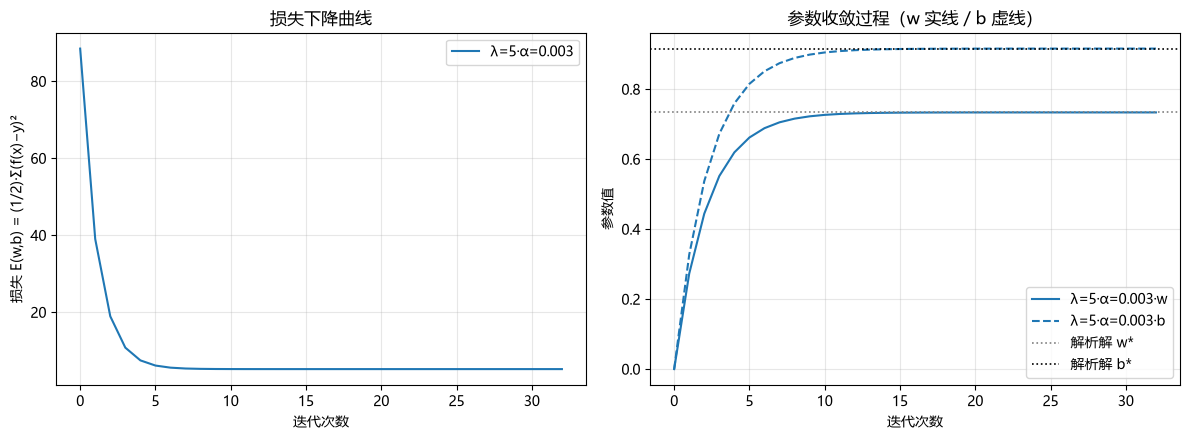

In [7]:
# 绘制损失、模型参数随迭代次数的变化曲线（封装成函数，支持对比多组训练结果）
import matplotlib.pyplot as plt

# 中文显示设置（Windows 优先，兼容 macOS）
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Arial Unicode MS', 'PingFang SC', 'Hiragino Sans GB']  # 把 Windows 中文字体放到最前面，原 macOS 字体保留兜底
plt.rcParams['axes.unicode_minus'] = False  # 保持不变


def plot_gd_curves(histories, labels, w_star=None, b_star=None):
    """绘制梯度下降训练的损失曲线与参数收敛曲线。

    参数:
        histories: list，一个或多个训练记录（gradient_descent 返回的 history，
                   形状 (iters+1, 3)，每行 [损失E, w, b]，含第 0 点初始状态）
        labels:    list，与 histories 一一对应的标签（说明对应的超参数组）
        w_star / b_star: 可选，解析解 w、b，用于画对照虚线
    """
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
    colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple']

    for h, lab, c in zip(histories, labels, colors):
        iters = np.arange(len(h))
        # 左图：损失 E 随迭代次数的变化（对应课件 p32 下图）
        ax1.plot(iters, h[:, 0], color=c, label=lab)
        # 右图：参数收敛过程（w 实线、b 虚线，同色 = 同一组训练）
        ax2.plot(iters, h[:, 1], color=c, ls='-', label=f'{lab}·w')
        ax2.plot(iters, h[:, 2], color=c, ls='--', label=f'{lab}·b')

    if w_star is not None:
        ax2.axhline(w_star, color='gray', ls=':', lw=1.2, label='解析解 w*')
    if b_star is not None:
        ax2.axhline(b_star, color='black', ls=':', lw=1.2, label='解析解 b*')

    ax1.set_xlabel('迭代次数')
    ax1.set_ylabel('损失 E(w,b) = (1/2)·Σ(f(x)−y)²')
    ax1.set_title('损失下降曲线')
    ax1.legend()
    ax1.grid(alpha=0.3)

    ax2.set_xlabel('迭代次数')
    ax2.set_ylabel('参数值')
    ax2.set_title('参数收敛过程（w 实线 / b 虚线）')
    ax2.legend()
    ax2.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


# 调用：当前这组 Ridge 训练结果（之后调学习率时，把多组 history 一起传入即可对比）
plot_gd_curves([gd_history],
               [f'λ={LAMBDA_1V:g}·α={LEARNING_RATE}'],
               w_star=w_ra, b_star=b_ra)

### 调学习率观察收敛变化；

α=0.001  迭代  103 次 → w=0.733547, b=0.915964, E=5.218101


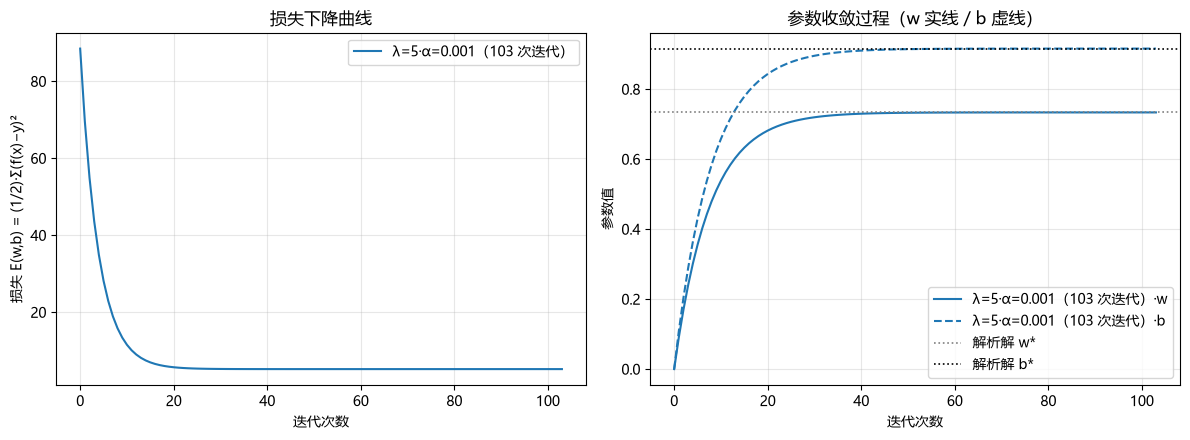

α=0.005  迭代   16 次 → w=0.733548, b=0.915966, E=5.218101


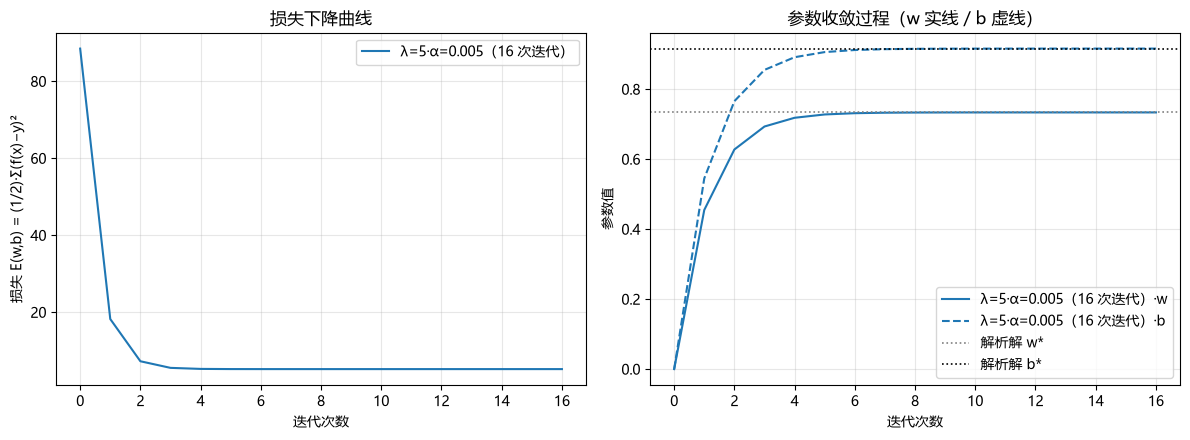

α=0.016  迭代  717 次 → w=0.733555, b=0.915966, E=5.218101


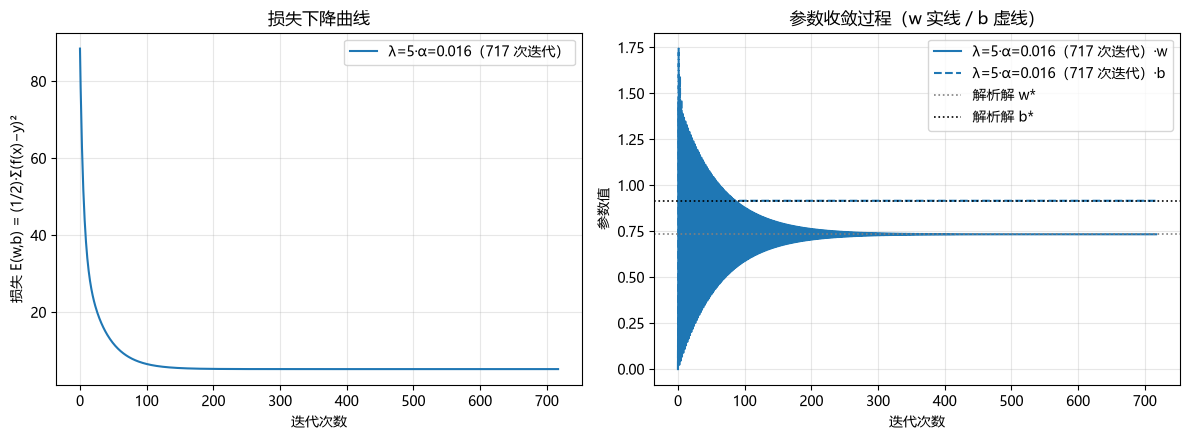

In [8]:
# 调学习率观察收敛变化：对比 3 组不同学习率 α 的训练过程
# 训练直接复用上一单元格的 gradient_descent，绘图直接复用 plot_gd_curves

# 三组学习率的设计（Ridge λ=5 时稳定上界 ≈ 2/(Σx²+λ) ≈ 0.016）：
#   α=0.001 偏小 → 每步挪得少，收敛慢、曲线平滑
#   α=0.005 适中 → 快速平稳收敛
#   α=0.016 偏大 → 逼近稳定上界，参数来回震荡后收敛（超过 0.0161 则发散，可自行验证）
learning_rates = [0.001, 0.005, 0.016]

histories, labels = [], []
for i,lr in enumerate(learning_rates):
    w_lr, b_lr, h = gradient_descent(x, y, lr=lr)
    histories.append(h)
    labels.append(f'λ={LAMBDA_1V:g}·α={lr}（{len(h) - 1} 次迭代）')
    print(f'α={lr:<6} 迭代 {len(h) - 1:4d} 次 → w={w_lr:.6f}, b={b_lr:.6f}, E={h[-1, 0]:.6f}')

    # 三组损失曲线 / 参数收敛曲线同图对比，虚线为解析解
    plot_gd_curves([histories[i]], [labels[i]], w_star=w_ra, b_star=b_ra)



### 可视化：训练散点 + 拟合直线

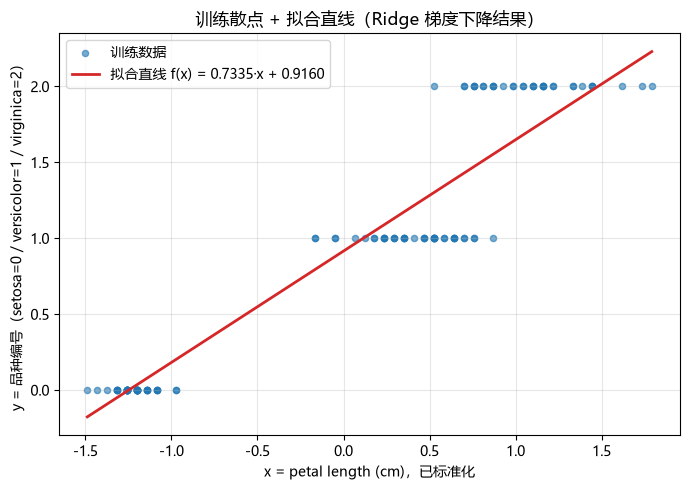

In [9]:
# 可视化：训练散点 + 拟合直线
# 使用最初始超参数（λ=LAMBDA_1V=5、α=LEARNING_RATE=0.003）Ridge 训练的 gd_history 最终参数 w_gd, b_gd
# 对应课件《单变量-梯度下降法》p32 上图：预测函数（红线）+ 训练数据（散点）
import matplotlib.pyplot as plt

# 中文显示设置（Windows 优先，兼容 macOS）
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Arial Unicode MS', 'PingFang SC', 'Hiragino Sans GB']  # 把 Windows 中文字体放到最前面，原 macOS 字体保留兜底
plt.rcParams['axes.unicode_minus'] = False  # 保持不变


def plot_fit_line(x, y, w, b):
    """绘制单变量线性回归的训练散点 + 拟合直线 f(x) = w·x + b。

    参数:
        x, y: 训练数据（形状 (m,)）
        w, b: 模型参数（梯度下降结果 w_gd, b_gd）
    """
    fig, ax = plt.subplots(figsize=(7, 5))

    ax.scatter(x, y, s=20, alpha=0.6, color='tab:blue', label='训练数据')
    x_line = np.linspace(x.min(), x.max(), 100)        # 在 x 取值范围内取点画直线
    ax.plot(x_line, w * x_line + b, color='tab:red', lw=2,
            label=f'拟合直线 f(x) = {w:.4f}·x + {b:.4f}')

    ax.set_xlabel('x = petal length (cm)，已标准化')
    ax.set_ylabel('y = 品种编号（setosa=0 / versicolor=1 / virginica=2）')
    ax.set_title('训练散点 + 拟合直线（Ridge 梯度下降结果）')
    ax.legend()
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


# 调用：最初始超参数训练得到的参数
plot_fit_line(x, y, w_gd, b_gd)

# 2变量

## 解析解法

<img src="../hw_01/第二章%20线性模型_pages/多变量-解析解法/page_039.png" width="50%">

重点：编程实现矩阵形式，实现上述ppt最后一行表达式

### ★新增：Ridge（二范数正则化）版本
课件 part2 p24/p28：**E(w) = 1/(2m)·[ ‖Xw−y‖² + λ·‖w̃‖₂² ]**，**w̃ = [w1, w2]（偏置 w0 不惩罚）**

<img src="./第二章%20线性模型_part2_pages/ridge回归/page_028.png" width="52%">

**正规方程多加 λ×惩罚对角阵（课件 p28）：w = ( XᵀX + λ·diag(0,1,…,1) )⁻¹·Xᵀy**

In [10]:
# 2变量线性回归 —— 解析解（Ridge 二范数正则化版；课件 part2《ridge回归》p28，向量形式）
# 模型: y = w0·1 + w1·x1 + w2·x2 = w^T·x        （课件 p33：令 w0=b, x0=1）
# 损失: E(w) = 1/(2m)·[ ‖Xw − y‖² + λ·‖w̃‖₂² ]   （课件 p24；w̃ = [w1, w2]，偏置 w0 不惩罚）
# ★Ridge 正规方程: w = (XᵀX + λ·D)⁻¹·Xᵀ·y，D = diag(0,1,…,1)   （课件 p28，D 首元素为 0 → 偏置不惩罚）
# λ=0 时即普通线性回归正规方程 w = (XᵀX)⁻¹·Xᵀy（课件 part1 p39），用作对照
import numpy as np

# ---------- 1 准备 2 变量数据（与单变量一节保持一致的目标值） ----------
y = y_train.map({'setosa': 0, 'versicolor': 1, 'virginica': 2}).to_numpy()
m = len(y)                                            # 训练样本数
X0 = x_train[['petal length (cm)', 'petal width (cm)']].to_numpy()   # (m, 2)

# ---------- 2 构造设计矩阵 X：每行一个样本，首列补 1（课件 p36） ----------
X = np.hstack([np.ones((m, 1)), X0])                  # (m, 3)

# ---------- 3 构造惩罚矩阵 D 与测试集（Ridge 新增） ----------
D = np.eye(X.shape[1])                                # ★单位矩阵
D[0, 0] = 0.0                                         # ★首元素置 0 → 偏置 w0 不参与惩罚
y_test_num = y_test.map({'setosa': 0, 'versicolor': 1, 'virginica': 2}).to_numpy()   # ★测试集目标值同规则映射
X_test_2v = np.hstack([np.ones((len(y_test_num), 1)),                        # ★测试集设计矩阵（首列补 1，同训练集）
                       x_test[['petal length (cm)', 'petal width (cm)']].to_numpy()])  # ★测试集两特征
m_test = len(y_test_num)                              # ★测试样本数 = 30

# ---------- 4 λ 扫描：同一个正规方程只调 λ（λ=0 行即普通线性回归，作对照） ----------
for lam in [0, 1, 5, 10]:
    w_r = np.linalg.inv(X.T @ X + lam * D) @ X.T @ y                        # Ridge 正规方程（课件 p28）
    E_tr = np.sum((X @ w_r - y) ** 2) / (2 * m)                             # 训练误差（1/(2m) 尺度）
    E_te = np.sum((X_test_2v @ w_r - y_test_num) ** 2) / (2 * m_test)       # 测试误差（同样口径）
    print(f'λ={lam:<4} Ridge 解析解 w = {w_r.round(6)}, E_train(1/2m) = {E_tr:.6f}, E_test(1/2m) = {E_te:.6f}')

# ---------- 5 选定 λ 的解析解（后续梯度下降/绘图都以此为对照） ----------
LAMBDA_2V = 5.0                                       # 测试误差最小的 λ（见上扫描）
w_ridge = np.linalg.inv(X.T @ X + LAMBDA_2V * D) @ X.T @ y            # (3,) = [b, w1, w2]
b2, w1, w2 = w_ridge[0], w_ridge[1], w_ridge[2]       # w[0] 即偏置 b
E = np.sum((X @ w_ridge - y) ** 2) / 2                # E(1/2·Σ 口径，与前文一致)
E_te = np.sum((X_test_2v @ w_ridge - y_test_num) ** 2) / (2 * m_test)  # 测试误差

print(f'\n样本数 m        = {m}')
print(f'Ridge(λ=5) 解析解 b (w0)   = {b2:.6f}   （偏置不被收缩）')
print(f'Ridge(λ=5) 解析解 w1 (长度) = {w1:.6f}')
print(f'Ridge(λ=5) 解析解 w2 (宽度) = {w2:.6f}')
print(f'损失 E(1/2·Σ)   = {E:.6f}（数据拟合项，未含正则惩罚）')
print(f'损失 E(1/2m·Σ)  = {E / (2 * m):.6f}  (单变量解析解为 0.032070，加入 w2 后更小)')
print(f'测试 E(1/2m·Σ)  = {E_te:.6f}  (λ=0 普通回归为 0.029703，下降约 5.4% = 正则化的"小改进")')
print(f'参数二范数 ‖w̃‖₂ = {np.linalg.norm(w_ridge[1:]):.4f}  (λ=0 时为 0.5984，接近 0 但不为 0，课件 p27)')


λ=0    Ridge 解析解 w = [0.915966 0.225171 0.554436], E_train(1/2m) = 0.023737, E_test(1/2m) = 0.029703
λ=1    Ridge 解析解 w = [0.915966 0.262067 0.514233], E_train(1/2m) = 0.023784, E_test(1/2m) = 0.028731
λ=5    Ridge 解析解 w = [0.915966 0.316569 0.446778], E_train(1/2m) = 0.024140, E_test(1/2m) = 0.028102
λ=10   Ridge 解析解 w = [0.915966 0.333301 0.414451], E_train(1/2m) = 0.024661, E_test(1/2m) = 0.028768

样本数 m        = 119
Ridge(λ=5) 解析解 b (w0)   = 0.915966   （偏置不被收缩）
Ridge(λ=5) 解析解 w1 (长度) = 0.316569
Ridge(λ=5) 解析解 w2 (宽度) = 0.446778
损失 E(1/2·Σ)   = 2.872676（数据拟合项，未含正则惩罚）
损失 E(1/2m·Σ)  = 0.012070  (单变量解析解为 0.032070，加入 w2 后更小)
测试 E(1/2m·Σ)  = 0.028102  (λ=0 普通回归为 0.029703，下降约 5.4% = 正则化的"小改进")
参数二范数 ‖w̃‖₂ = 0.5476  (λ=0 时为 0.5984，接近 0 但不为 0，课件 p27)


## 梯度下降法

### 绘制损失、模型参数随迭代次数的变化曲线

<img src="../hw_01/第二章%20线性模型_pages/多变量-梯度下降法/page_040.png" width="50%">

重点：矩阵形式实现上面梯度下降法

<img src="./第二章%20线性模型_part2_pages/ridge回归/page_028.png" width="52%">


**★新增 Ridge**：梯度多加二范数项 **λ·D·w**（课件 part2 p28 红圈 (λ/m)·wⱼ 的向量形式，**D 使偏置 w0 不被收缩**）

迭代次数      = 333
梯度下降 w    = [0.915966 0.316584 0.446763]   （w0 即偏置 b，偏置不被收缩）
最终损失 E    = 3.622243（含正则项 λ‖w̃‖²/2）
(对照解析解   = [0.915966 0.316569 0.446778])


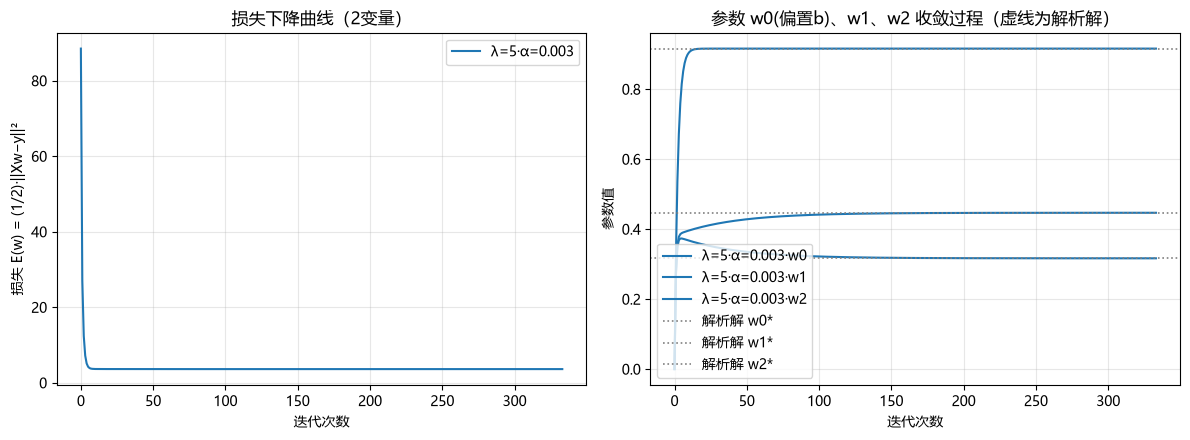

In [11]:
# 2变量线性回归 —— 梯度下降法（Ridge 二范数正则化版；课件《多变量-梯度下降法》p40 + part2 p24/p28）
# 更新规则（批量梯度下降，向量形式，与解析解共用上面的设计矩阵 X、目标值 y、惩罚矩阵 D）：
#   w := w − α·[ Xᵀ(Xw − y) + λ·D·w ]
#   —— 课件 p28 更新式 wⱼ := (1−αλ/m)·wⱼ − α·(1/m)·Σ(f(xᵢ)−yᵢ)·xᵢⱼ 两侧同乘 m 的等价形式，
#      整个参数向量一次赋值，天然满足"同时更新 w_j"；D·w 只收缩 w1、w2，偏置 w0 不被收缩
# 损失函数（课件 p40 系数 1/2 + part2 p24 正则项）：E(w) = (1/2)·[ ‖Xw − y‖² + λ·‖D·w‖₂² ]
import numpy as np
import matplotlib.pyplot as plt

# ==================== 超参数与停止阈值（集中定义，便于统一调整） ====================
LEARNING_RATE_2V = 0.003   # 学习率 α（Ridge λ=5 时稳定上界 2/λmax(XᵀX+λD) ≈ 0.0083，过大会发散）
MAX_ITERS_2V     = 5000    # 最大迭代次数
TOL_2V           = 1e-10   # 停止阈值：相邻两次损失变化 < TOL 即认为已收敛
W_INIT_2V        = None    # 起始点 w 向量（None = 零向量 [0, 0, 0]）
# （正则化强度 λ 沿用解析解单元格的 LAMBDA_2V = 5.0，作为函数默认参数）


# ==================== 梯度下降主体（唯一的 Ridge 版本函数，λ 可调） ====================
def gradient_descent_vec(X, y, lr=LEARNING_RATE_2V, lam=LAMBDA_2V, max_iter=MAX_ITERS_2V,
                         tol=TOL_2V, w=None):
    """向量形式批量梯度下降求解 Ridge 回归（二范数正则化，D 使偏置 w0 不被收缩）。

    参数:
        lam: 正则化强度 λ（对比不同 λ 时传入不同取值即可，无需另写函数）

    返回: (w, history)
        history: (iters+1, n+2) 数组，每行是 [损失E, w0, w1, w2]，
                 含第 0 次迭代前的初始状态，供绘制损失/参数变化曲线。
    """
    w = np.zeros(X.shape[1]) if w is None else w.copy()
    history = [((np.sum((X @ w - y) ** 2) + lam * np.sum((D @ w) ** 2)) / 2, *w)]   # 记录初始状态（E 含 λ‖w̃‖²/2）
    for t in range(max_iter):
        w = w - lr * (X.T @ (X @ w - y) + lam * (D @ w))   # 同步更新（一次向量运算，课件 p28）
        history.append(((np.sum((X @ w - y) ** 2) + lam * np.sum((D @ w) ** 2)) / 2, *w))
        if abs(history[-2][0] - history[-1][0]) < tol:    # 损失几乎不再下降 → 停止
            break
    return w, np.array(history)


def plot_gd_curves_n(histories, labels, w_star=None):
    """绘制多变量梯度下降的损失曲线与各参数收敛曲线（plot_gd_curves 的多变量推广版）。

    参数:
        histories: list，训练记录（gradient_descent_vec 返回的 history，
                   每行 [损失E, w0, w1, …, wn]）
        labels:    list，与 histories 一一对应的标签
        w_star:    可选，解析解参数向量，用于画对照虚线
    """
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
    colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple']

    for h, lab, c in zip(histories, labels, colors):
        iters = np.arange(len(h))
        ax1.plot(iters, h[:, 0], color=c, label=lab)
        for j in range(h.shape[1] - 1):                   # 逐个参数画收敛曲线
            ax2.plot(iters, h[:, j + 1], color=c, label=f'{lab}·w{j}')

    if w_star is not None:                                # 解析解对照（虚线）
        for j, ws in enumerate(np.atleast_1d(w_star)):
            ax2.axhline(ws, color='gray', ls=':', lw=1.2, label=f'解析解 w{j}*')

    ax1.set_xlabel('迭代次数')
    ax1.set_ylabel('损失 E(w) = (1/2)·||Xw−y||²')
    ax1.set_title('损失下降曲线（2变量）')
    ax1.legend()
    ax1.grid(alpha=0.3)

    ax2.set_xlabel('迭代次数')
    ax2.set_ylabel('参数值')
    ax2.set_title('参数 w0(偏置b)、w1、w2 收敛过程（虚线为解析解）')
    ax2.legend()
    ax2.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


# ==================== 运行（沿用解析解单元格的 X、y、D，λ 取默认 LAMBDA_2V） ====================
w_gd_vec, gd_hist_vec = gradient_descent_vec(X, y)

print(f'迭代次数      = {len(gd_hist_vec) - 1}')
print(f'梯度下降 w    = {w_gd_vec.round(6)}   （w0 即偏置 b，偏置不被收缩）')
print(f'最终损失 E    = {gd_hist_vec[-1, 0]:.6f}（含正则项 λ‖w̃‖²/2）')
print(f'(对照解析解   = {w_ridge.round(6)})')

plot_gd_curves_n([gd_hist_vec], [f'λ={LAMBDA_2V:g}·α={LEARNING_RATE_2V}'], w_star=w_ridge)


### 调学习率观察收敛变化；

=== α = 0.001 ===
迭代次数   = 939
梯度下降 w = [0.915966 0.316596 0.446752]
最终损失 E = 3.622243
(对照 Ridge 解析解 = [0.915966 0.316569 0.446778])



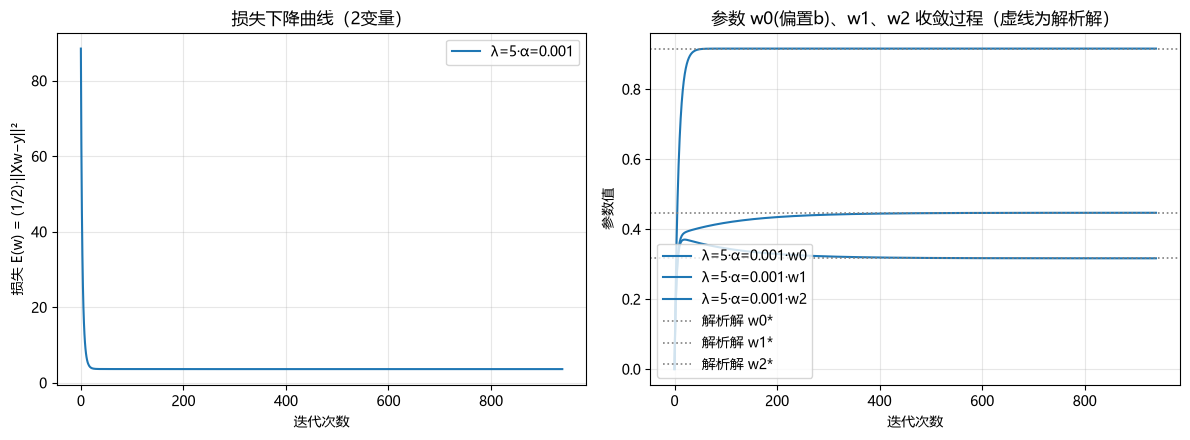

=== α = 0.003 ===
迭代次数   = 333
梯度下降 w = [0.915966 0.316584 0.446763]
最终损失 E = 3.622243
(对照 Ridge 解析解 = [0.915966 0.316569 0.446778])



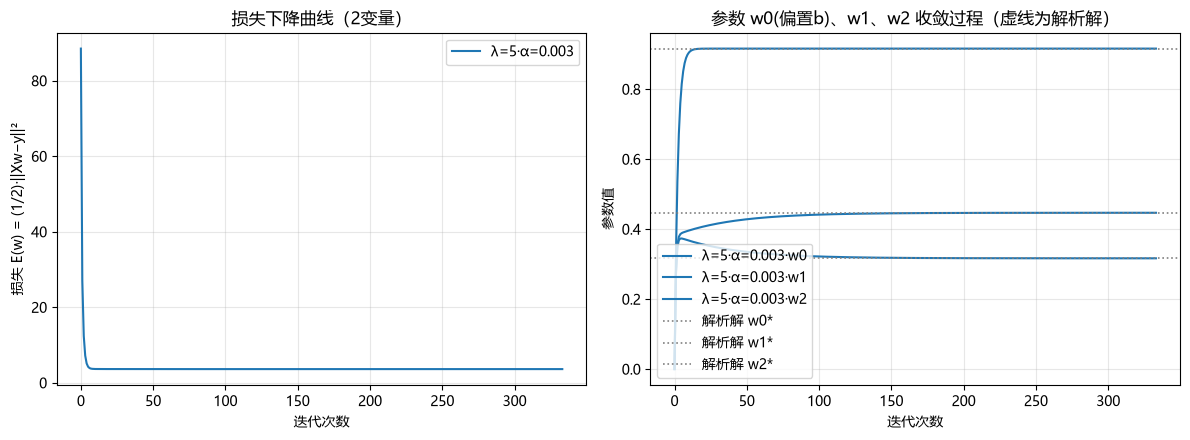

=== α = 0.008 ===
迭代次数   = 146
梯度下降 w = [0.915966 0.316571 0.446774]
最终损失 E = 3.622243
(对照 Ridge 解析解 = [0.915966 0.316569 0.446778])



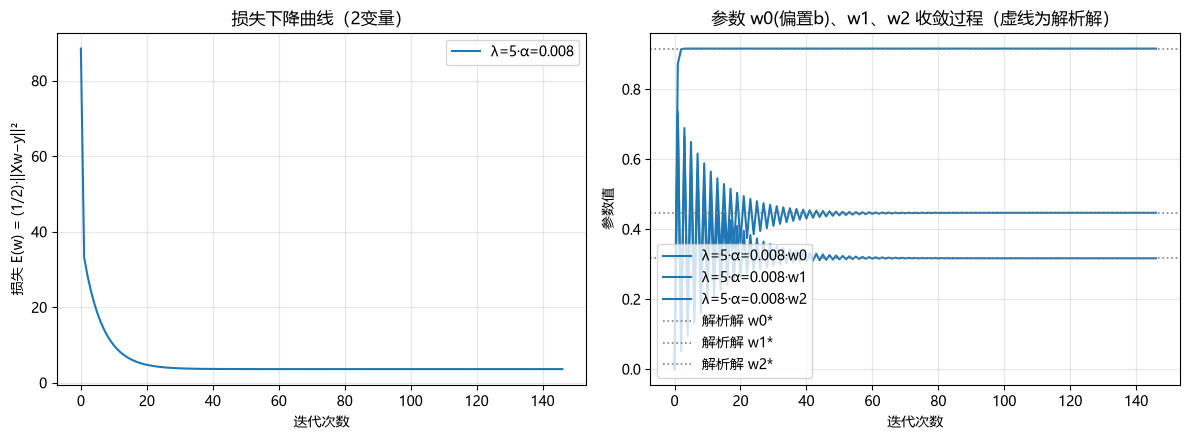

In [12]:
# 调学习率观察收敛变化（2变量）：对比 3 组不同学习率 α，分三次训练并分别输出
# 训练复用上一单元格的 gradient_descent_vec，绘图复用 plot_gd_curves_n（参考单变量的方式）
#
# 三组学习率的设计（Ridge λ=5 时稳定上界 2/λmax(XᵀX+λD) ≈ 0.0083）：
#   α=0.001 偏小 → 每步挪得少，收敛慢、曲线平滑
#   α=0.003 适中 → 平稳收敛（默认值）
#   α=0.008 偏大 → 接近稳定上界，参数来回震荡后收敛（超过 0.0083 则发散，可自行验证）
learning_rates_2v = [0.001, 0.003, 0.008]

for lr in learning_rates_2v:
    # ---- 训练一组学习率 ----
    w_lr, h_lr = gradient_descent_vec(X, y, lr=lr)

    # ---- 打印该组结果 ----
    print(f'=== α = {lr} ===')
    print(f'迭代次数   = {len(h_lr) - 1}')
    print(f'梯度下降 w = {w_lr.round(6)}')
    print(f'最终损失 E = {h_lr[-1, 0]:.6f}')
    print(f'(对照 Ridge 解析解 = {w_ridge.round(6)})\n')

    # ---- 单独绘制该组的损失/参数收敛曲线（分三次输出） ----
    plot_gd_curves_n([h_lr], [f'λ={LAMBDA_2V:g}·α={lr}'], w_star=w_ridge)

### 可视化：训练散点 + 拟合平面

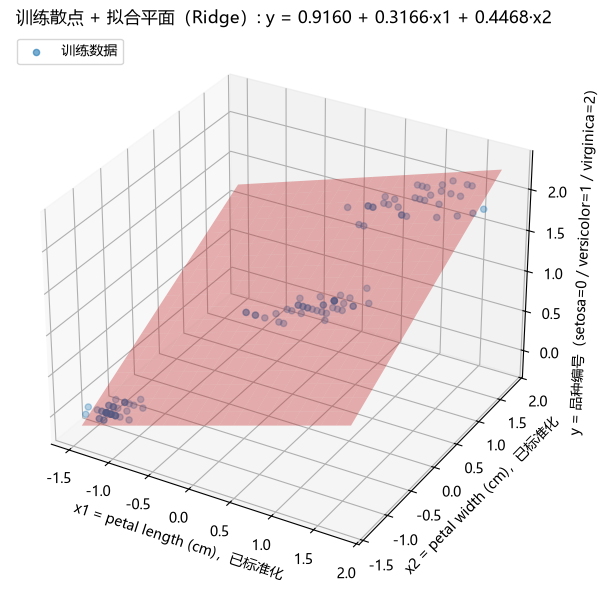

In [10]:
# 可视化：训练散点 + 拟合平面（2变量线性回归，三维图）
# 使用默认超参数（λ=LAMBDA_2V=5、α=LEARNING_RATE_2V=0.003）Ridge 训练的 w_gd_vec，与解析解几乎一致
# 拟合平面: y = w0 + w1·x1 + w2·x2
import matplotlib.pyplot as plt

# 中文显示设置（Windows 优先，兼容 macOS）
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Arial Unicode MS', 'PingFang SC', 'Hiragino Sans GB']  # 把 Windows 中文字体放到最前面，原 macOS 字体保留兜底
plt.rcParams['axes.unicode_minus'] = False  # 保持不变


def plot_fit_plane(X0, y, w):
    """绘制 2 变量线性回归的训练散点 + 拟合平面（3D 图）。

    参数:
        X0: (m, 2) 两个特征的原始数据（不含 1 列）
        y:  (m,)   目标值
        w:  (3,)   模型参数 [w0(偏置b), w1, w2]（梯度下降结果 w_gd_vec）
    """
    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(projection='3d')

    # 训练散点
    ax.scatter(X0[:, 0], X0[:, 1], y, s=20, alpha=0.6,
               color='tab:blue', label='训练数据')

    # 拟合平面：在两特征的取值范围内铺网格，按模型计算 z
    g1 = np.linspace(X0[:, 0].min(), X0[:, 0].max(), 20)
    g2 = np.linspace(X0[:, 1].min(), X0[:, 1].max(), 20)
    G1, G2 = np.meshgrid(g1, g2)
    ax.plot_surface(G1, G2, w[0] + w[1] * G1 + w[2] * G2,
                    alpha=0.35, color='tab:red')

    ax.set_xlabel('x1 = petal length (cm)，已标准化')
    ax.set_ylabel('x2 = petal width (cm)，已标准化')
    ax.set_zlabel('y = 品种编号（setosa=0 / versicolor=1 / virginica=2）')
    ax.set_title(f'训练散点 + 拟合平面（Ridge）: y = {w[0]:.4f} + {w[1]:.4f}·x1 + {w[2]:.4f}·x2')
    ax.legend(loc='upper left')

    plt.tight_layout()
    plt.show()


# 调用：默认超参数训练得到的参数
plot_fit_plane(X0, y, w_gd_vec)